In [1]:
import numpy as np
import pandas as pd
from datetime import datetime as dt

import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['font.size'] = 13

In [3]:
from pathlib import Path
import sys

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data_lake" / "config.json").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root")

PROJECT_ROOT = find_project_root()
PYTHON_DIR = PROJECT_ROOT / "python"
if str(PYTHON_DIR) not in sys.path:
    sys.path.insert(0, str(PYTHON_DIR))
from utils import load_config

config_file_path = PROJECT_ROOT / "data_lake" / "config.json"

config_params = load_config(config_file_path)
bronze_folder = config_params.get('BRONZE_FOLDER', {})
river_name_column = config_params.get('RIVER_NAME_COLUMN', {})
ts_analysis_data = PROJECT_ROOT / config_params.get('TS_ANALYSIS_FOLDER', {})
bronze_folder = PROJECT_ROOT / bronze_folder
filter_data_path = bronze_folder / 'combined_filtered_data.csv'

In [4]:
filtered_data = pd.read_csv(filter_data_path)

river = filtered_data[river_name_column].iloc[0]

# print datasets general info
filtered_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Post_ID        318 non-null    int64  
 1   Post_Name      318 non-null    object 
 2   Post_Code      318 non-null    object 
 3   Riverbas_Name  318 non-null    object 
 4   WaterLab_Name  318 non-null    object 
 5   Latitude       318 non-null    float64
 6   Longitude      318 non-null    float64
 7   Controle_Date  318 non-null    object 
 8   Azot           50 non-null     float64
 9   BSK5           311 non-null    float64
 10  Zavisli        317 non-null    float64
 11  Kisen          312 non-null    object 
 12  Sulfat         310 non-null    float64
 13  Hlorid         310 non-null    float64
 14  Amoniy         310 non-null    object 
 15  Nitrat         303 non-null    object 
 16  Nitrit         311 non-null    float64
 17  Fosfat         310 non-null    float64
 18  SPAR      

In [5]:
required_columns = {'Controle_Date', river_name_column, 'BSK5', 'HSK'}
missing_columns = required_columns.difference(filtered_data.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

duplicate_count = int(filtered_data.duplicated().sum())
if duplicate_count:
    raise ValueError(f'Filtered data contains {duplicate_count} duplicate rows')

In [6]:
# change date values from string to datetime object
date_formats = [
    '%Y-%m-%d',
    '%d.%m.%Y'
]

filtered_data['_Raw_Date_String'] = filtered_data['Controle_Date'].astype(str)

filtered_data['Controle_Date'] = pd.to_datetime(
    filtered_data['_Raw_Date_String'],
    format=date_formats[0],
    errors='coerce'
)

for fmt in date_formats[1:]:
    mask = filtered_data['Controle_Date'].isna()

    if not mask.any():
        break

    raw_data_to_parse = filtered_data.loc[mask, '_Raw_Date_String']

    parsed_subset = pd.to_datetime(raw_data_to_parse, format=fmt, errors='coerce')

    filtered_data.loc[mask, 'Controle_Date'] = parsed_subset

filtered_data.drop(columns=['_Raw_Date_String'], inplace=True)

filtered_data = filtered_data.rename(columns={'Controle_Date': 'date'})

print(filtered_data['date'])

0     2004-01-06
1     2004-01-14
2     2004-02-17
3     2004-03-08
4     2004-03-22
         ...    
313   2023-11-13
314   2024-02-12
315   2024-01-30
316   2024-03-12
317   2025-02-10
Name: date, Length: 318, dtype: datetime64[ns]


In [7]:
filtered_data = filtered_data.sort_values('date', ascending=True)
filtered_data.dropna(subset=['BSK5', 'HSK'], inplace=True)

print(filtered_data['date'])

1     2004-01-14
2     2004-02-17
4     2004-03-22
5     2004-04-21
6     2004-05-18
         ...    
313   2023-11-13
315   2024-01-30
314   2024-02-12
316   2024-03-12
317   2025-02-10
Name: date, Length: 286, dtype: datetime64[ns]


In [11]:
print(filtered_data[['date', 'HSK', 'BSK5']])

          date   HSK  BSK5
1   2004-01-14  60.5  3.60
2   2004-02-17  55.5  4.93
4   2004-03-22  52.5  2.20
5   2004-04-21  64.0  4.56
6   2004-05-18  89.1  2.20
..         ...   ...   ...
313 2023-11-13  48.0  3.00
315 2024-01-30   7.7  3.10
314 2024-02-12  22.0  6.40
316 2024-03-12  26.0  6.00
317 2025-02-10  55.0  2.45

[286 rows x 3 columns]


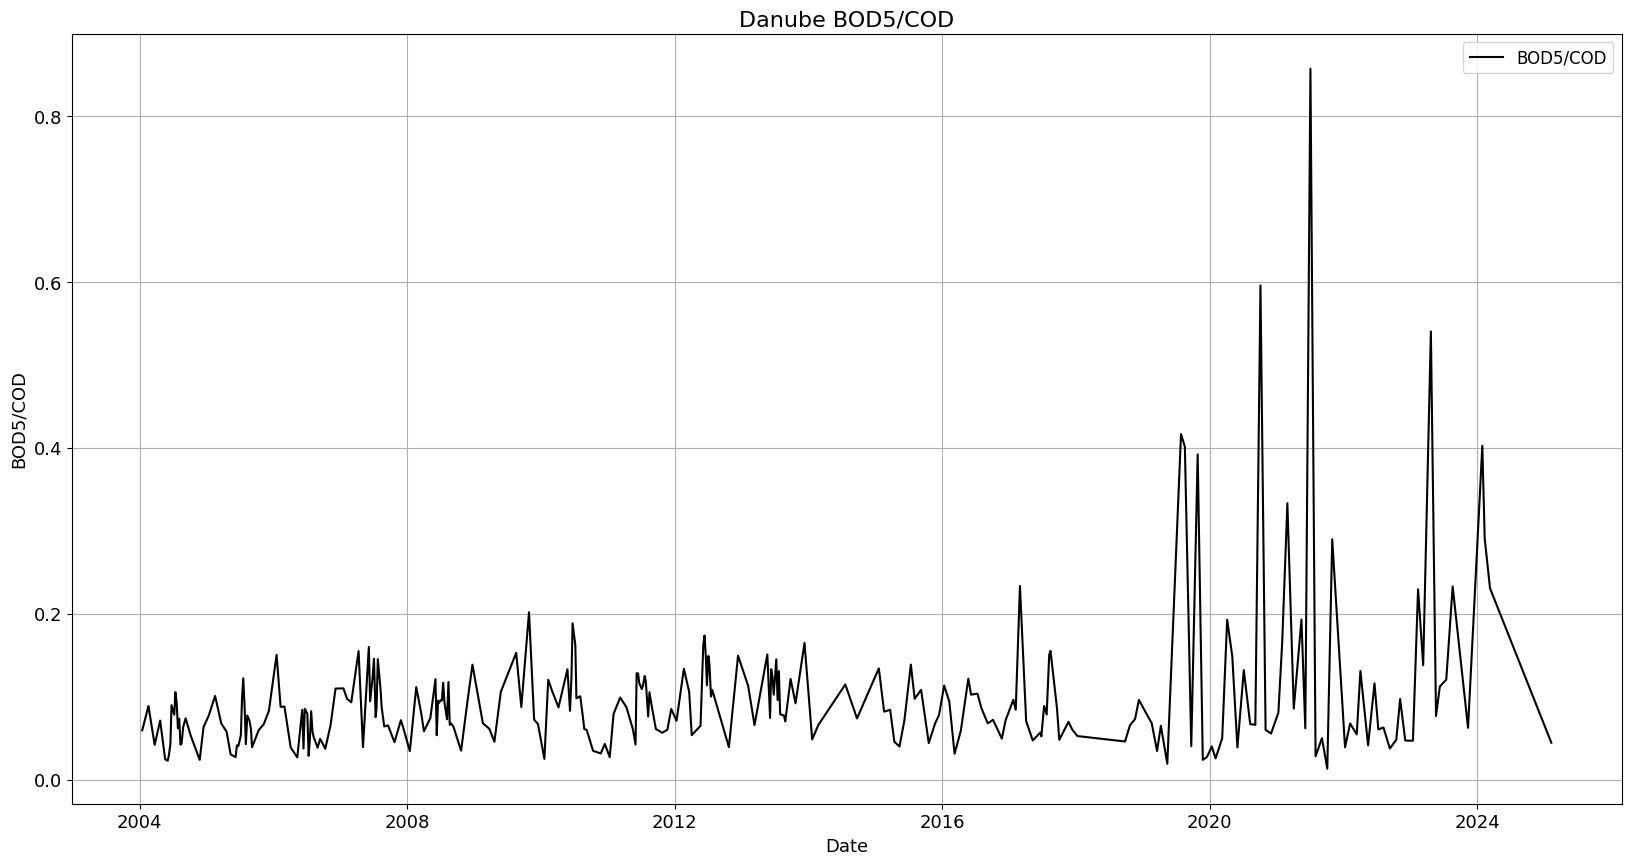

In [17]:
def plot():
    fig, ax = plt.subplots(figsize=(20,10))

    ax.plot(filtered_data['date'], filtered_data['BSK5']/filtered_data['HSK'], color='black', label=f'BOD5/COD')

    ax.legend(prop={"size":12})
    #ax.set_facecolor('#383838')
    ax.set_ylabel('BOD5/COD')
    ax.set_xlabel('Date')  
    ax.set_title(f'Danube BOD5/COD',
          fontsize=16)
    ax.grid(True)

    fig.savefig(f"{ts_analysis_data}/{river}_BSK5_HSK_corr.png", dpi=300, bbox_inches='tight')

plot()

In [15]:
filtered_data.head()

,Post_ID,Post_Name,Post_Code,Riverbas_Name,WaterLab_Name,Latitude,Longitude,date,Azot,BSK5,...,Amoniy,Nitrat,Nitrit,Fosfat,SPAR,Permanganat,HSK,Fitoplan,Atrazin,Simazin
1,27315,"оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...",ЧЕР ДУНАЙ 0114 0000 0000 0000 0000 0000 01 51,Дунай,Лабораторія моніторингу вод Дунайського РОВР,45.622511,28.62125,2004-01-14,NaN,3.60,...,0.25,0.03,0.003,0.040,0.12,8.8,60.5,NaN,NaN,NaN
2,27315,"оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...",ЧЕР ДУНАЙ 0114 0000 0000 0000 0000 0000 01 51,Дунай,Лабораторія моніторингу вод Дунайського РОВР,45.622511,28.62125,2004-02-17,NaN,4.93,...,0.16,0.03,0.003,0.038,0.12,8.5,55.5,NaN,NaN,NaN
4,27315,"оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...",ЧЕР ДУНАЙ 0114 0000 0000 0000 0000 0000 01 51,Дунай,Лабораторія моніторингу вод Дунайського РОВР,45.622511,28.62125,2004-03-22,NaN,2.20,...,0.19,0.05,0.006,0.076,0.15,9.4,52.5,NaN,NaN,NaN
5,27315,"оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...",ЧЕР ДУНАЙ 0114 0000 0000 0000 0000 0000 01 51,Дунай,Лабораторія моніторингу вод Дунайського РОВР,45.622511,28.62125,2004-04-21,NaN,4.56,...,0.16,0.02,0.002,0.026,0.12,9.1,64.0,NaN,NaN,NaN
6,27315,"оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...",ЧЕР ДУНАЙ 0114 0000 0000 0000 0000 0000 01 51,Дунай,Лабораторія моніторингу вод Дунайського РОВР,45.622511,28.62125,2004-05-18,NaN,2.20,...,0.2999999999999999,0.05,0.003,0.026,0.13,8.9,89.1,NaN,NaN,NaN
